### Agentic RAG with LangGraph


In [1]:
from typing import  List
from langgraph.graph import StateGraph, END
from langchain_core.documents import Document
from dotenv import load_dotenv
load_dotenv()

True

### Load LLM 

In [2]:

import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()

api_key = os.getenv("GEMINI_KEY")
if not api_key:
    raise ValueError("Failed to load Gemini key")
MODEL_NAME = os.getenv("MODELNM")
if not MODEL_NAME:
    raise ValueError("Faild to laod Model")

llm = ChatGoogleGenerativeAI(
    model=MODEL_NAME,
    max_retries=2,
    api_key=api_key,
)

# question = "What is RAG? Explain briefly."

# messages = [
#     (
#         "system",
#         "You are a helpful assistant. Answer user queries concisely.",
#     ),
#     ("human", question),
# ]

# ai_msg = llm.invoke(messages)
# content = ai_msg.content[0]
# cast(dict[str, str], content)["text"]


In [3]:
print("Configured model:", MODEL_NAME)

Configured model: gemini-3.5-flash-lite


## Sample Documents Loading, Chunking, Embeddings 

In [4]:
### Sample Document and vector store 
# Sample documents  for demostation 
from typing import Any , cast
from langchain_community.document_loaders import PyMuPDFLoader, DirectoryLoader

pdf_docs = DirectoryLoader(
    path= "../Data/Pdf_files/",
    glob="**/*.pdf",
    loader_cls= cast(Any , PyMuPDFLoader),
    show_progress= True

)
pdf_docs = pdf_docs.load()


C:\Users\shind\AppData\Local\Temp\ipykernel_22992\432898371.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader, DirectoryLoader
100%|██████████| 6/6 [00:01<00:00,  5.96it/s]


## Chunking 

In [5]:
## Chunking 
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 1000,
    chunk_overlap = 200
)
if not pdf_docs:
    raise ValueError(f"Documents not loaded ")
chunks = text_splitter.split_documents(cast(List[Document], pdf_docs))

### Embeddings 

In [6]:

# import numpy as np
# from collections.abc import Sequence
# from langchain_huggingface import HuggingFaceEmbeddings


# class EmbeddingManager:
#     """Generate normalized embeddings for document chunks."""

#     def __init__( self, model_name: str = "sentence-transformers/all-MiniLM-L6-v2", device: str = "cpu") -> None:
        
#         self.model_name = model_name

#         print(f"Loading embedding model: {model_name}")

#         self.model = HuggingFaceEmbeddings(
#             model_name=model_name,
#             model_kwargs={"device": device},
#             encode_kwargs={"normalize_embeddings": True},
#         )

#         # Read dimension from a real embedding once.
#         test_vector = self.model.embed_query("Embedding dimension check")
#         self.embedding_dimension = len(test_vector)

#         print(
#             "Embedding model initialized. "
#             f"Dimension: {self.embedding_dimension}"
#         )

#     def generate_embeddings( self, texts: Sequence[str] ) -> np.ndarray:
#         """Embed non-empty text inputs; return shape (n_texts, dimension)."""

#         if not texts:
#             raise ValueError("Text list cannot be empty.")

#         if any(not text.strip() for text in texts):
#             raise ValueError("Input contains empty or whitespace-only text.")

#         vectors = self.model.embed_documents(list(texts))
#         embeddings = np.asarray(vectors, dtype=np.float32)

#         expected_shape = (len(texts), self.embedding_dimension)
#         if embeddings.shape != expected_shape:
#             raise ValueError(
#                 f"Unexpected embedding shape {embeddings.shape}; "
#                 f"expected {expected_shape}."
#             )

#         return embeddings


# # Initialize once and reuse
# embedding_manager = EmbeddingManager()

# embedding_vectors = embedding_manager.generate_embeddings(
#     [document.page_content for document in chunks]
# )

# print("Embedding shape:", embedding_vectors.shape)


### Vector Store

In [7]:

from pathlib import Path
import hashlib
import json

from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings


# Resolve the storage path from the project directory in Jupyter
CURRENT_DIRECTORY = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in (CURRENT_DIRECTORY, *CURRENT_DIRECTORY.parents)
        if (path / "Data").is_dir()
    ),
    CURRENT_DIRECTORY,
)

PERSIST_DIRECTORY = PROJECT_ROOT / "Data" / "vector_store"
COLLECTION_NAME = "Programming_Courses"


# Initialize the embedding model once per notebook kernel session
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True},
)


def create_vector_store(chunks):
    """
    Store document chunks and embeddings persistently in ChromaDB.
    Avoid duplicate records by generating deterministic IDs.
    """

    if not chunks:
        raise ValueError("No document chunks were provided.")

    # Initialize or connect to the existing collection
    vector_store = Chroma(
        collection_name=COLLECTION_NAME,
        embedding_function=embeddings,
        persist_directory=str(PERSIST_DIRECTORY),
        collection_metadata={"hnsw:space": "cosine"},
    )

    # Generate deterministic IDs for each chunk
    ids = []

    for doc in chunks:
        metadata_string = json.dumps(
            doc.metadata,
            sort_keys=True,
            default=str,
        )

        unique_content = (
            f"{doc.page_content}\n{metadata_string}"
        )

        doc_id = hashlib.sha256(
            unique_content.encode("utf-8")
        ).hexdigest()

        ids.append(doc_id)

    # Find which records already exist
    existing_records = vector_store.get(
        ids=ids,
        include=[],
    )

    existing_ids = set(existing_records["ids"])

    # Separate new and existing records
    new_docs = []
    new_ids = []

    updated_docs = []
    updated_ids = []

    for doc, doc_id in zip(chunks, ids):
        if doc_id in existing_ids:
            updated_docs.append(doc)
            updated_ids.append(doc_id)
        else:
            new_docs.append(doc)
            new_ids.append(doc_id)

    # Insert only new records
    if new_docs:
        vector_store.add_documents(
            documents=new_docs,
            ids=new_ids,
        )

    # Update records that already exist
    if updated_docs:
        vector_store.update_documents(
            ids=updated_ids,
            documents=updated_docs,
        )

    # Display results
    print(f"New records added: {len(new_docs)}")
    print(f"Existing records updated: {len(updated_docs)}")
    print(
        f"Total records in ChromaDB: "
        f"{vector_store._collection.count()}"
    )

    return vector_store


# Create or reuse the vector store
vector_store = create_vector_store(chunks=chunks)


e:\RAG Project\RAG_System\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2651.97it/s]


New records added: 0
Existing records updated: 918
Total records in ChromaDB: 918


### Retriver 

In [15]:

from langchain_core.prompts import ChatPromptTemplate

def retrieve_relevant_docs(question: str, k: int = 4, threshold: float = 0.45):
    """Retrieve only chunks whose cosine similarity meets the threshold."""

    results = vector_store.similarity_search_with_relevance_scores(
        question,
        k=k,
    )

    relevant_docs = [
        doc
        for doc, score in results
        if score >= threshold
    ]

    # print(f"Retrieved candidates: {len(results)}")
    # print(f"Relevant documents: {len(relevant_docs)}")

    # for doc, score in results:
    #     print(f"Score: {score:.3f} | Kept: {score >= threshold}")
    #     print(doc.page_content[:150].replace("\n", " "))

    return relevant_docs

# question = "What are the limitations of the stack implementation in C?"

# docs = retrieve_relevant_docs(question)

# print(f"\nRelevant documents returned: {len(docs)}")

# for i, doc in enumerate(docs, start=1):
#     print(f"\n--- Document {i} ---")
#     print(doc.page_content)


### Agent State Defination

In [9]:
from typing import TypedDict,List
from langchain_core.documents import Document
class AgentState(TypedDict):
    question: str
    documents: List[Document]
    answer : str
    needs_retrieval: bool

#### Agent Functions


In [10]:
from langchain_google_genai.chat_models import (
    GoogleRateLimitError,
    GoogleAPIError,
    GoogleAuthenticationError,
    GoogleInvalidRequestError,
    GoogleModelNotFoundError,
)

def decide_retrieval(state: AgentState) -> AgentState:
    """Decide whether the question should search the PDF knowledge base."""

    question = state["question"].strip().lower()

    # Skip retrieval only for clearly conversational messages.
    direct_response_phrases = [
        "hello",
        "hi",
        "hey",
        "good morning",
        "good afternoon",
        "good evening",
        "thank you",
        "thanks",
        "bye",
        "goodbye",
    ]

    is_conversation = (
        question in direct_response_phrases
        or not question
    )

    needs_retrieval = not is_conversation

    return {
        **state,
        "needs_retrieval": needs_retrieval,
    }


def retrieve_docs(state: AgentState) -> AgentState:
    """Retrieve only documents that meet the relevance threshold."""

    question = state["question"]

    relevant_docs = retrieve_relevant_docs(question=question)

    return {
        **state,
        "documents": relevant_docs,
    }


def generate_answer(state: AgentState) -> AgentState:
    """Generate an answer grounded in retrieved documents."""

    question = state["question"]
    documents = state.get("documents", [])
    needs_retrieval = state.get("needs_retrieval", False)

    if needs_retrieval and not documents:
        return {
            **state,
            "answer": (
                "I couldn't find relevant information in the "
                "available PDF documents to answer this question."
            ),
        }

    try:
        if not needs_retrieval:
            response = llm.invoke(
                f"Answer this conversational message concisely: {question}"
            )

        else:
            context = "\n\n".join(
                doc.page_content for doc in documents
            )

            prompt = ChatPromptTemplate.from_messages([
                (
                    "system",
                    """Answer the question using only the provided context.

                    Rules:
                    1. Include only facts directly supported by the context.
                    2. Do not add facts from general knowledge or make unsupported inferences.
                    3. Preserve distinctions between separate examples, implementations,
                       and concepts described in the context.
                    4. If the context only partially answers the question, state what it
                       supports and explicitly identify what information is missing.
                    5. If the context does not answer the question, say so clearly.
                    
                    Context:
                    {context}"""
                ),
                ("human", "{question}"),
            ])

            chain = prompt | llm

            response = chain.invoke({
                "context": context,
                "question": question,
            })

        # Support both string and list-of-content-block responses.
        if isinstance(response.content, str):
            answer = response.content
        else:
            answer = "".join(
                block.get("text", "")
                for block in response.content
                if isinstance(block, dict)
                and isinstance(block.get("text"), str)
            )
            
        return {
                **state,
                "answer": answer,
            }
    
    except GoogleRateLimitError as exc:
        print(f"Gemini rate limit exceeded: {exc}")
        answer = (
            "The language model request was rate-limited. "
            "Please wait before trying again."
        )

    except GoogleAuthenticationError as exc:
        print(f"Gemini authentication failed: {exc}")
        answer = (
            "The language model authentication failed. "
            "Check your API key and configuration."
        )

    except GoogleModelNotFoundError as exc:
        print(f"Gemini model not found: {exc}")
        answer = (
            "The configured language model could not be found. "
            "Check the model name."
        )

    except GoogleInvalidRequestError as exc:
        print(f"Gemini rejected the request: {exc}")
        answer = (
            "The language model rejected the request. "
            "Check the request configuration and input."
        )

    except GoogleAPIError as exc:
        print(f"Gemini API error: {exc}")
        answer = (
            "The language model service encountered an error. "
            "Please try again later."
        )

    except Exception as exc:
        print(f"Unexpected generation error: {type(exc).__name__}: {exc}")
        answer = (
            "I couldn't generate an answer because the language "
            "model request failed. Please try again later."
        )

    return {
        **state,
        "answer": answer,
    }

#### Conditional Logic

In [11]:
def should_retrive(state: AgentState) -> str:
    """ Determine the next step based on retrieval decision """
    if state["needs_retrieval"]:
        return "retrieve"
    else:
        return "generate"



#### Build The Graph

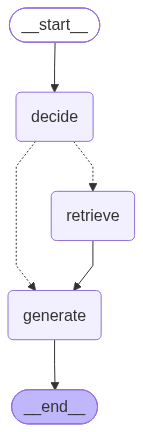

In [12]:
## Create the state Graph
workflow = StateGraph(AgentState)

# Add nodes
workflow.add_node("decide", decide_retrieval)
workflow.add_node("retrieve", retrieve_docs)
workflow.add_node("generate", generate_answer)

workflow.set_entry_point("decide")

workflow.add_conditional_edges(
    "decide",
    should_retrive,
    {
        "retrieve":"retrieve",
        "generate":"generate"
    }

)

# Add edges 
workflow.add_edge("retrieve", "generate")
workflow.add_edge("generate", END)

# compile the graph 
app = workflow.compile()
app

### Test the Agentic Question


In [13]:
def ask_question(question:str):
    """ Helper function to ask a question and get the answer"""

    initial_state = {
        "question": question,
        "documents": [],
        "answer":"",
        "needs_retrieval": False
    }
    result = app.invoke(initial_state) # type: ignore
    return result

In [16]:
# Test with a question that shoud trigger retrival
test_questions = [
    "Hi",
    "What is quantum computing?",
    "How does the C programming language implement a stack?",
]


for question in test_questions:
    result = ask_question(question)

    print(
        f"\n"
        f"{question!r} -> \n"
        f"Answer: {result['answer']}\n"
    )




'Hi' -> 
Answer: Hi there! How can I help you today?


'What is quantum computing?' -> 
Answer: I couldn't find relevant information in the available PDF documents to answer this question.


'How does the C programming language implement a stack?' -> 
Answer: Based on the provided context, the C programming language itself does not provide a heap, garbage collection, or operations to deal directly with composite objects like lists or arrays (other than static definition and the stack discipline provided by local variables of functions). 

Specifically regarding the implementation of a stack in the provided text:
* The stack and its associated information (such as the stack index) are stored in external variables (variables defined outside of any function) so they are accessible to the `push` and `pop` functions but hidden from `main`.
* The `push` function (`void push(double f)`) pushes a value onto the stack.
* The `pop` function (`double pop(void)`) checks if the stack index (`sp`) 